### **Problem 2**

Consider the task of interpolating the function f(x) = 1/ 1+x2 on the interval [−5, 5]. Using
equispaced nodes with n = 5, 10, 15 and 20, interpolate the function using the methods below:

#### Problem 2 Write Up

The spline methods work the best, out of the two spline method sthe clamped cubic spline works the best possibly due to the end point restrcitions

#### Problem 3 Write Up

The chebyschev points decrease the error, especially at the endpoints, because the nodes are clustered at the endpoints resulting in a more accurate approximation

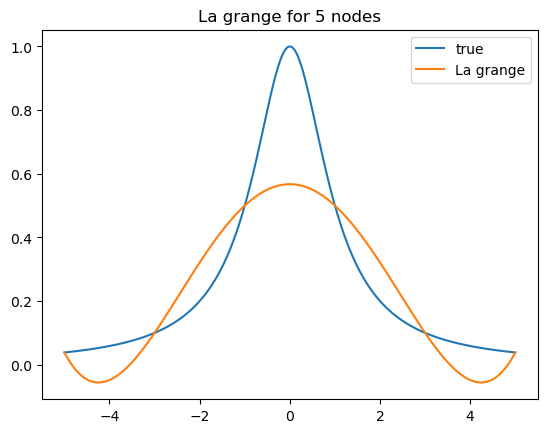

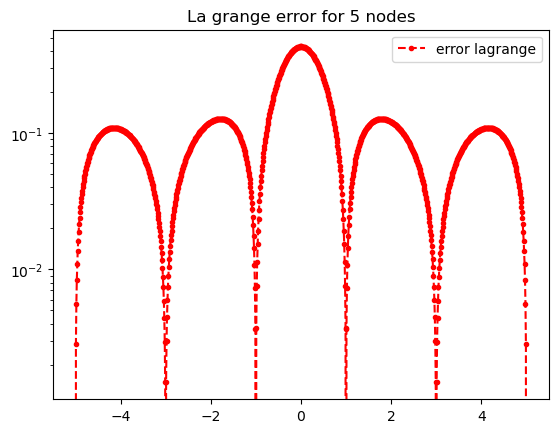

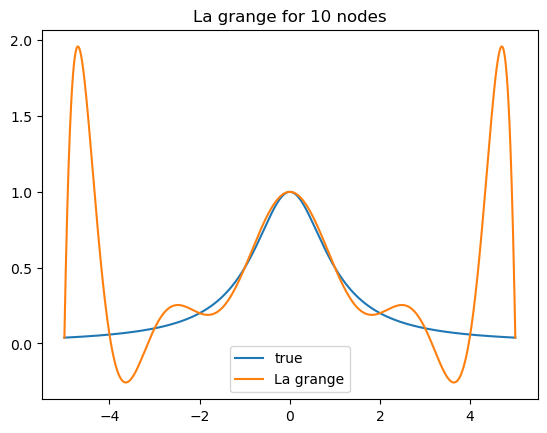

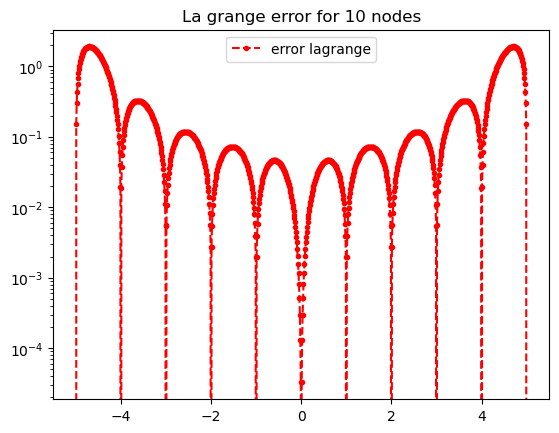

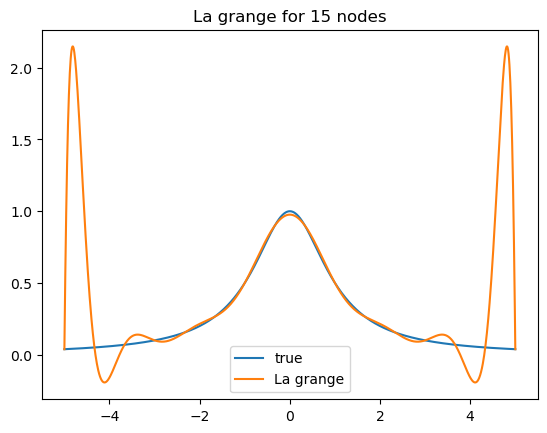

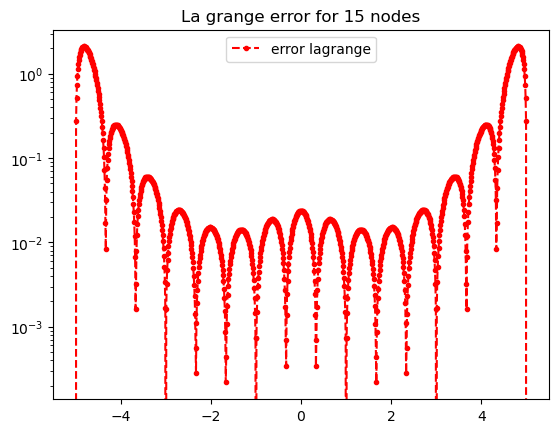

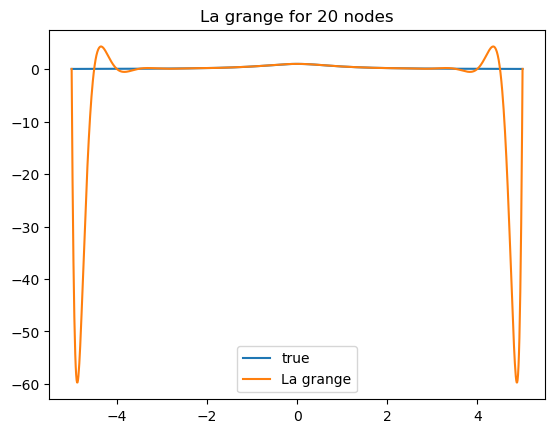

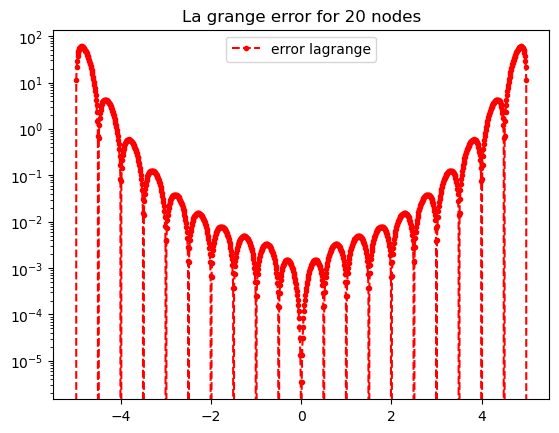

In [46]:
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt

def plot(N):

    f = lambda x: 1/(1+x**2)

   
    ''' create equispaced interpolation nodes'''
    xint = np.linspace(-5,5,N+1)
    
    ''' create interpolation data'''
    yint = f(xint)
    
    ''' create points for evaluating the Lagrange interpolating polynomial'''
    Neval = 1000
    xeval = np.linspace(-5,5,Neval+1)
    yeval_l= np.zeros(Neval+1) # lagrange
  
    '''Initialize and populate the first columns of the 
     divided difference matrix. We will pass the x vector'''
    y = np.zeros( (N+1, N+1) )
     
    
    ''' evaluate lagrange poly '''
    for kk in range(Neval+1):
       yeval_l[kk] = eval_lagrange(xeval[kk],xint,yint, N)

    ''' create vector with exact values'''
    fex = f(xeval)
       

    plt.figure()    
    plt.plot(xeval,fex, label = 'true')
    plt.plot(xeval,yeval_l, label = 'La grange') 
    plt.title(f'La grange for {N} nodes')
    plt.legend()

    plt.figure() 
    err_l = abs(yeval_l-fex)
    plt.semilogy(xeval,err_l,'ro--', markersize=3,label='error lagrange')
    plt.title(f'La grange error for {N} nodes')
    plt.legend()
    plt.show()

def eval_lagrange(xeval,xint,yint,N):

    lj = np.ones(N+1)
    
    for count in range(N+1):
       for jj in range(N+1):
           if (jj != count):
              lj[count] = lj[count]*(xeval - xint[jj])/(xint[count]-xint[jj])

    yeval = 0.
    
    for jj in range(N+1):
       yeval = yeval + yint[jj]*lj[jj]
  
    return(yeval)


for n in range(1, 5):
    plot(5*n)

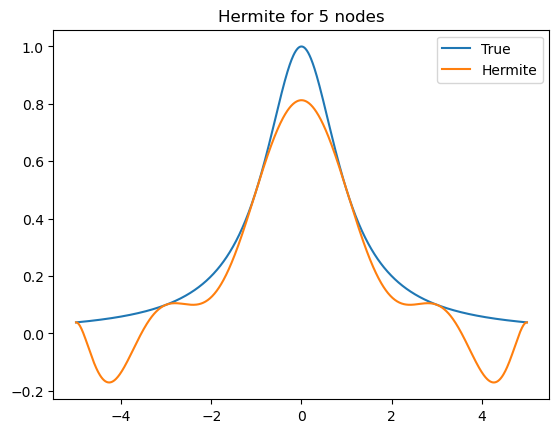

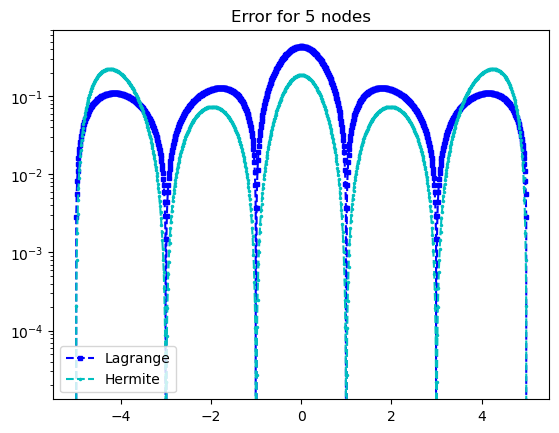

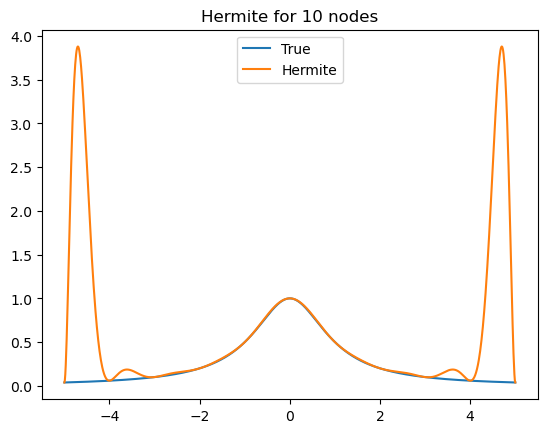

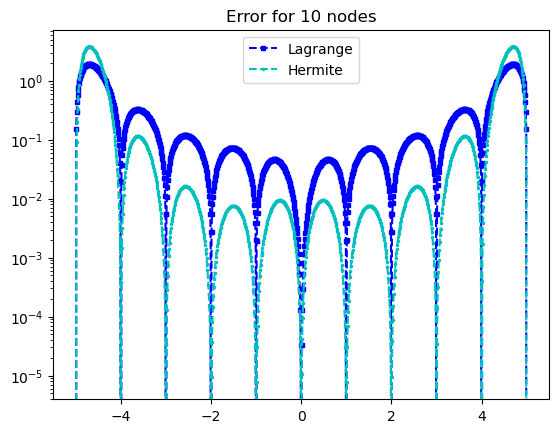

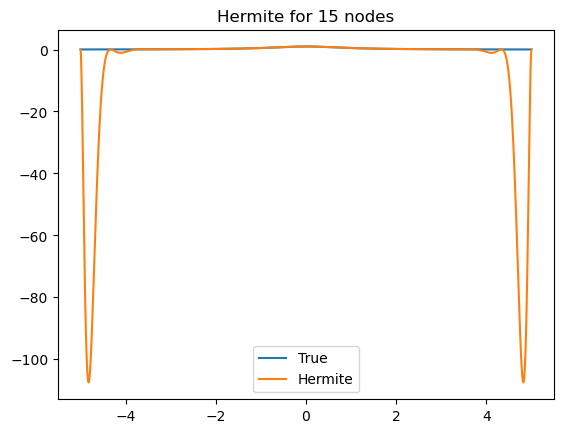

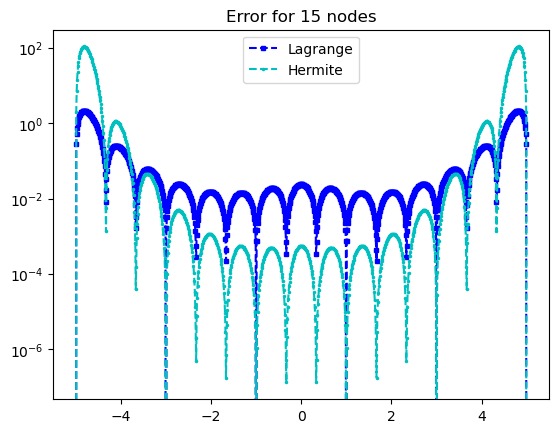

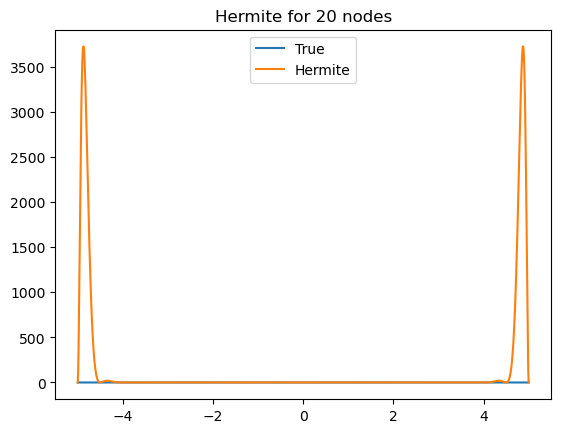

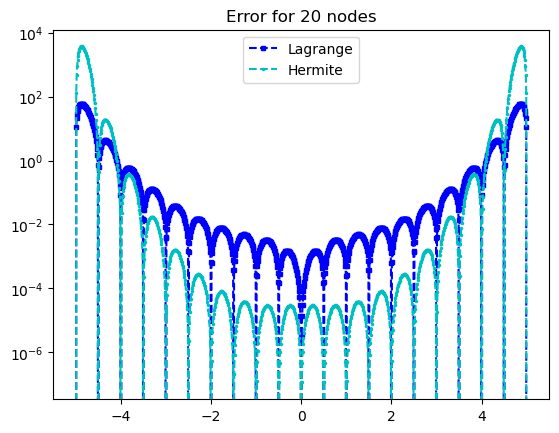

In [97]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.linalg as la
import math

def plot(N):


    f = lambda x: 1./(1.+x**2)
    fp = lambda x: -2*x/(1.+x**2)**2

    ''' interval'''
    a = -5
    b = 5
   
    ''' create equispaced interpolation nodes'''
    xint = np.linspace(a,b,N+1)
    
    ''' create interpolation data'''
    yint = np.zeros(N+1)
    ypint = np.zeros(N+1)
    for jj in range(N+1):
        yint[jj] = f(xint[jj])
        ypint[jj] = fp(xint[jj])
    
    ''' create points for evaluating the Lagrange interpolating polynomial'''
    Neval = 1000
    xeval = np.linspace(a,b,Neval+1)
    yevalL = np.zeros(Neval+1)
    yevalH = np.zeros(Neval+1)
    for kk in range(Neval+1):
      yevalL[kk] = eval_lagrange(xeval[kk],xint,yint,N)
      yevalH[kk] = eval_hermite(xeval[kk],xint,yint,ypint,N)

    ''' create vector with exact values'''
    fex = np.zeros(Neval+1)
    for kk in range(Neval+1):
        fex[kk] = f(xeval[kk])
    
    
    plt.figure()
    plt.plot(xeval,fex, label = 'True')
    #plt.plot(xeval,yevalL,label='Lagrange') 
    plt.plot(xeval,yevalH,label='Hermite')
    plt.title(f'Hermite for {N} nodes')
    plt.legend()
    #plt.semilogy()
    plt.show()
         
    errL = abs(yevalL-fex)
    errH = abs(yevalH-fex)
    plt.figure()
    plt.semilogy(xeval,errL,'bs--', markersize = 3, label='Lagrange')
    plt.semilogy(xeval,errH,'c.--',markersize = 3, label='Hermite')
    plt.legend()
    plt.title(f'Error for {N} nodes')
    plt.show()            


def eval_hermite(xeval,xint,yint,ypint,N):

    ''' Evaluate all Lagrange polynomials'''

    lj = np.ones(N+1)
    for count in range(N+1):
       for jj in range(N+1):
           if (jj != count):
              lj[count] = lj[count]*(xeval - xint[jj])/(xint[count]-xint[jj])

    ''' Construct the l_j'(x_j)'''
    lpj = np.zeros(N+1)
#    lpj2 = np.ones(N+1)
    for count in range(N+1):
       for jj in range(N+1):
           if (jj != count):
#              lpj2[count] = lpj2[count]*(xint[count] - xint[jj])
              lpj[count] = lpj[count]+ 1./(xint[count] - xint[jj])
              

    yeval = 0.
    
    for jj in range(N+1):
       Qj = (1.-2.*(xeval-xint[jj])*lpj[jj])*lj[jj]**2
       Rj = (xeval-xint[jj])*lj[jj]**2
#       if (jj == 0):
#         print(Qj)
         
#         print(Rj)
#         print(Qj)
#         print(xeval)
 #        return
       yeval = yeval + yint[jj]*Qj+ypint[jj]*Rj
       
    return(yeval)
       


def eval_lagrange(xeval,xint,yint,N):

    lj = np.ones(N+1)
    
    for count in range(N+1):
       for jj in range(N+1):
           if (jj != count):
              lj[count] = lj[count]*(xeval - xint[jj])/(xint[count]-xint[jj])

    yeval = 0.
    
    for jj in range(N+1):
       yeval = yeval + yint[jj]*lj[jj]
  
    return(yeval)
  
    

for n in range(1, 5):
    plot(n*5)


nerr =  1.312750716583567


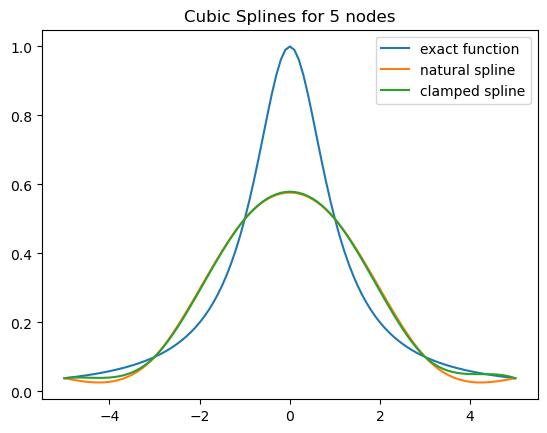

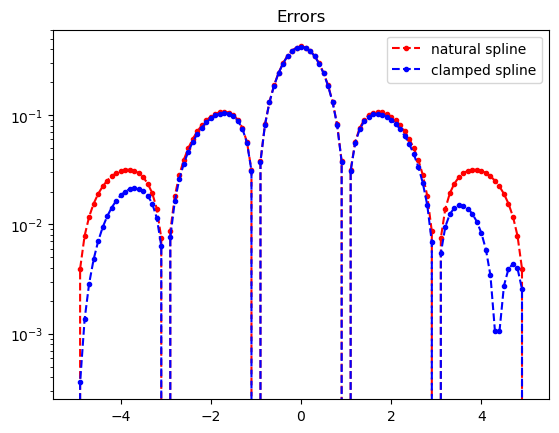

nerr =  0.07157970931037608


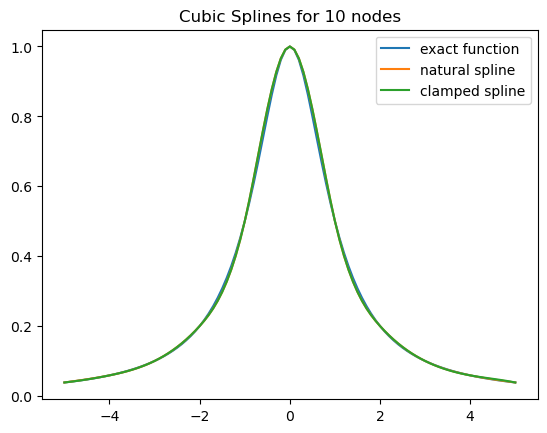

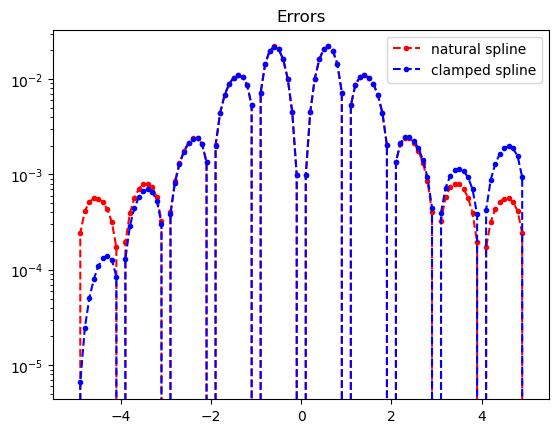

nerr =  0.0767467498644183


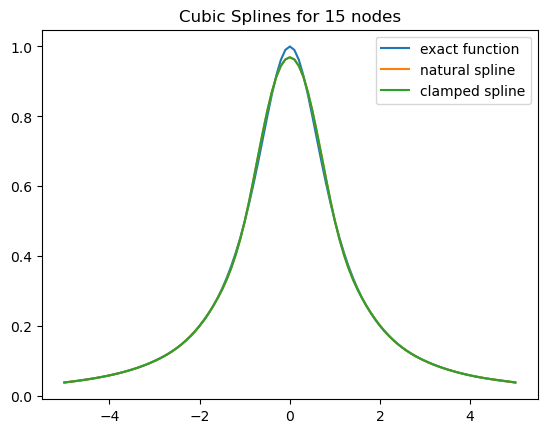

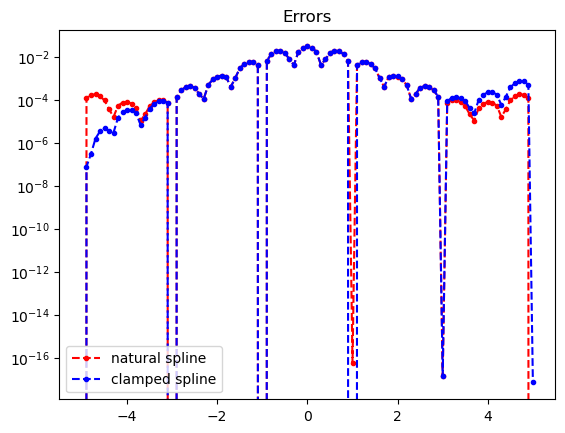

nerr =  0.00879288894489472


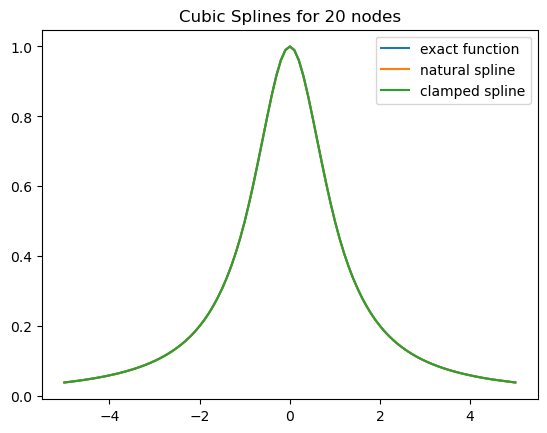

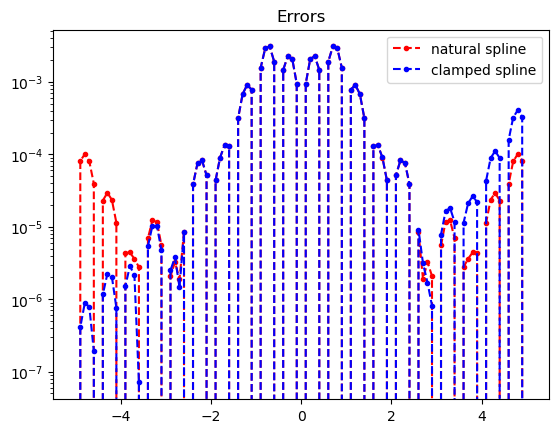

In [99]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numpy.linalg import inv 
from numpy.linalg import norm


def driver(Nint):
   
    f = lambda x: 1./(1.+x**2)
    fp = lambda x: -2*x/(1.+x**2)**2
    a = -5
    b = 5   
    
    ''' number of intervals'''
    xint2 = np.linspace(a,b,Nint+1)
# create chebychev nodes
#    xint = np.zeros(Nint+1)
#    for j in range(1,Nint+2):
#       xint[j-1] = np.cos(np.pi*(2*j-1)/(2*(Nint+1)))
# scale  for the interval
#    m = (b-a)/2 
#    c = (a+b)/2
#    xint = m*xint+c
#    xint = xint[::-1]
    xint = xint2
    yint = f(xint)
    yint2 = f(xint2)
    yp_b = np.zeros(2)
    yp_b[0] = fp(xint[0])
    yp_b[1] = fp(xint[Nint])
    
    ''' create points you want to evaluate at'''
    Neval = 100
    xeval =  np.linspace(xint[0],xint[Nint],Neval+1)
    
    
    
    (M,C,D) = create_natural_spline(yint2,xint2,Nint)
    (Mc,Cc,Dc) = create_clamped_spline(yint,yp_b, xint,Nint)    
    
    yeval = eval_cubic_spline(xeval,Neval,xint2,Nint,M,C,D)
    yevalc = eval_cubic_spline(xeval,Neval,xint,Nint,Mc,Cc,Dc)
    
#    print('yeval = ', yevalc)
    
    ''' evaluate f at the evaluation points'''
    fex = f(xeval)
        
    nerr = norm(fex-yeval)
    print('nerr = ', nerr)
    
    plt.figure()    
    plt.plot(xeval,fex,label='exact function')
    plt.plot(xeval,yeval,label='natural spline') 
    plt.plot(xeval,yevalc,label='clamped spline') 
    plt.title(f'Cubic Splines for {Nint} nodes')
    plt.legend()
    plt.show()
     
    err = abs(yeval-fex)
    errc = abs(yevalc-fex)
    plt.figure() 
    plt.semilogy(xeval,err,'ro--', markersize = 3, label='natural spline')
    plt.semilogy(xeval,errc,'bo--', markersize = 3, label='clamped spline')
    plt.title("Errors")
    plt.legend()
    plt.show()
    
def create_natural_spline(yint,xint,N):

#    create the right  hand side for the linear system
    b = np.zeros(N+1)
#  vector values
    h = np.zeros(N+1)  
    for i in range(1,N):
       hi = xint[i]-xint[i-1]
       hip = xint[i+1] - xint[i]
       b[i] = (yint[i+1]-yint[i])/hip - (yint[i]-yint[i-1])/hi
       h[i-1] = hi
       h[i] = hip

#  create matrix so you can solve for the M values
# This is made by filling one row at a time 
    A = np.zeros((N+1,N+1))
    A[0][0] = 1.0
    for j in range(1,N):
       A[j][j-1] = h[j-1]/6
       A[j][j] = (h[j]+h[j-1])/3 
       A[j][j+1] = h[j]/6
    A[N][N] = 1

    Ainv = inv(A)
    
    M  = Ainv.dot(b)

#  Create the linear coefficients
    C = np.zeros(N)
    D = np.zeros(N)
    for j in range(N):
       C[j] = yint[j]/h[j]-h[j]*M[j]/6
       D[j] = yint[j+1]/h[j]-h[j]*M[j+1]/6
    return(M,C,D)

def create_clamped_spline(yint,yp_b, xint,N):

#    create the right  hand side for the linear system
    b = np.zeros(N+1)
#  vector values
    h = np.zeros(N+1)  
    for i in range(1,N):
       hi = xint[i]-xint[i-1]
       hip = xint[i+1] - xint[i]
       b[i] = (yint[i+1]-yint[i])/hip - (yint[i]-yint[i-1])/hi
       h[i-1] = hi
       h[i] = hip
    b[0]  = -yp_b[0] +(yint[1]-yint[0])/h[0]
    b[N] = -yp_b[1] +(yint[N]-yint[N-1])/h[N-1]

#  create matrix so you can solve for the M values
# This is made by filling one row at a time 
    A = np.zeros((N+1,N+1))
    A[0][0] = h[0]/3.
    A[0][1] = h[0]/6.
    for j in range(1,N):
       A[j][j-1] = h[j-1]/6
       A[j][j] = (h[j]+h[j-1])/3 
       A[j][j+1] = h[j]/6
    A[N][N] = h[N-1]/3
    A[N][N-1] = h[N-1]/6

    Ainv = inv(A)
    
    M  = Ainv.dot(b)

#  Create the linear coefficients
    C = np.zeros(N)
    D = np.zeros(N)
    for j in range(N):
       C[j] = yint[j]/h[j]-h[j]*M[j]/6
       D[j] = yint[j+1]/h[j]-h[j]*M[j+1]/6
    return(M,C,D)


       
def eval_local_spline(xeval,xi,xip,Mi,Mip,C,D):
# Evaluates the local spline as defined in class
# xip = x_{i+1}; xi = x_i
# Mip = M_{i+1}; Mi = M_i

    hi = xip-xi
    yeval = (Mi*(xip-xeval)**3 +(xeval-xi)**3*Mip)/(6*hi) \
            + C*(xip-xeval) + D*(xeval-xi)
    return yeval 
    
    
def  eval_cubic_spline(xeval,Neval,xint,Nint,M,C,D):
    
    yeval = np.zeros(Neval+1)
    
    for j in range(Nint):
        '''find indices of xeval in interval (xint(jint),xint(jint+1))'''
        '''let ind denote the indices in the intervals'''
        atmp = xint[j]
        btmp= xint[j+1]
        
#   find indices of values of xeval in the interval
        ind= np.where((xeval >= atmp) & (xeval <= btmp))
        xloc = xeval[ind]
#        print('atmp =', atmp)
#       print('btmp =', btmp)
#        print('ind =', ind)
#       print('xloc =', xloc)
#        return

# evaluate the spline
        yloc = eval_local_spline(xloc,atmp,btmp,M[j],M[j+1],C[j],D[j])
#        print('yloc = ', yloc)
#   copy into yeval
        yeval[ind] = yloc

    return(yeval)
           
for n in range(1, 5):
    driver(5*n)               



### **Problem 3**

Repeat the experiment from the previous problem but with Chebychev nodes. How does this
impact the performance of the different interpolation techniques?

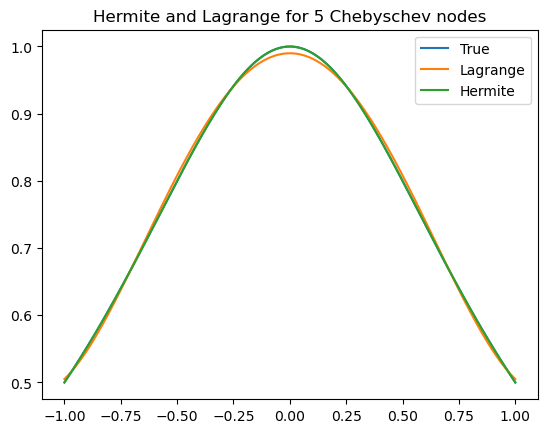

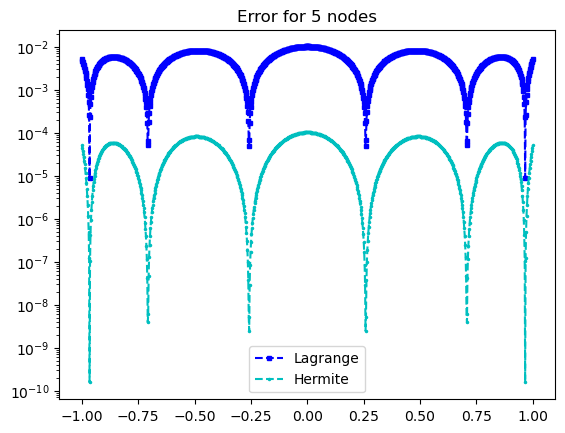

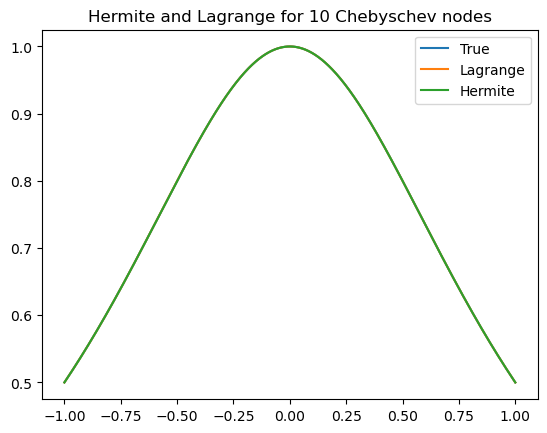

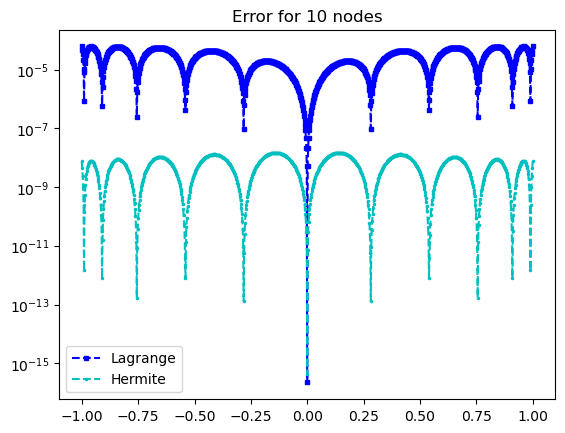

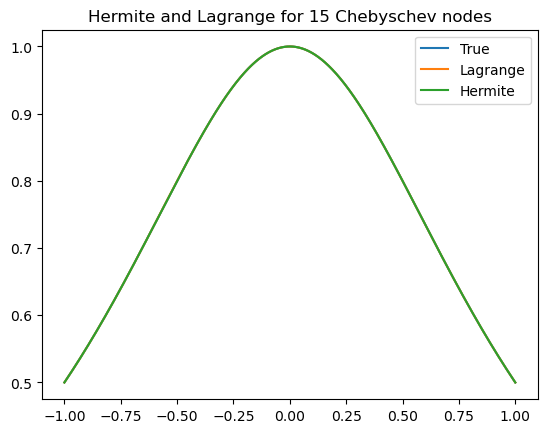

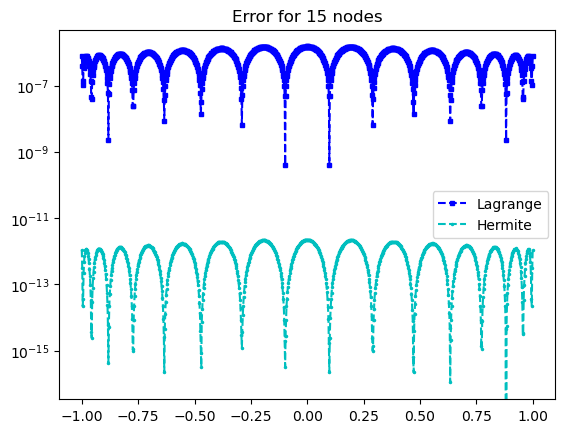

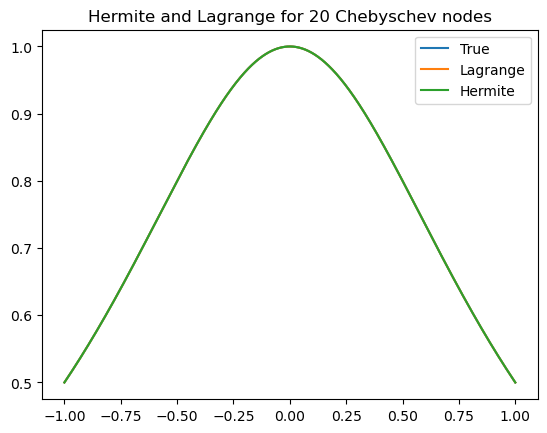

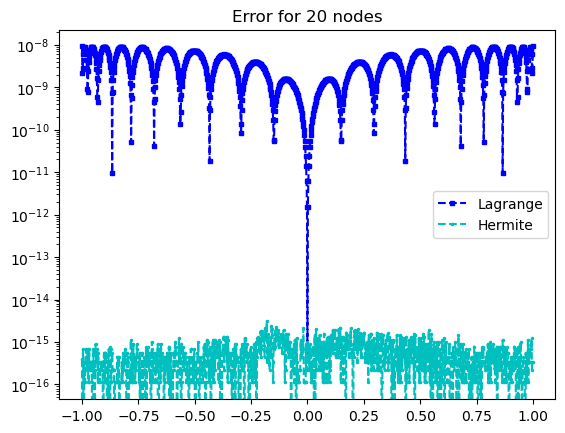

In [143]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.linalg as la
import math

def gen_cheby(N):
    xvals = np.zeros(N)

    for i in range(1, N+1):
        xvals[i-1] = np.cos(((2*i - 1) * np.pi) / (2*N))
        
    return xvals

def plot(N):


    f = lambda x: 1./(1.+x**2)
    fp = lambda x: -2*x/(1.+x**2)**2
   
    ''' create chebychev interpolation nodes'''
    xint = gen_cheby(N+1)
    
    ''' create interpolation data'''
    yint = np.zeros(N+1)
    ypint = np.zeros(N+1)
    for jj in range(N+1):
        yint[jj] = f(xint[jj])
        ypint[jj] = fp(xint[jj])
    
    ''' create points for evaluating the Lagrange interpolating polynomial'''
    Neval = 1000
    xeval = np.linspace(-1,1,Neval+1)
    yevalL = np.zeros(Neval+1)
    yevalH = np.zeros(Neval+1)
    for kk in range(Neval+1):
      yevalL[kk] = eval_lagrange(xeval[kk],xint,yint,N)
      yevalH[kk] = eval_hermite(xeval[kk],xint,yint,ypint,N)

    ''' create vector with exact values'''
    fex = np.zeros(Neval+1)
    for kk in range(Neval+1):
        fex[kk] = f(xeval[kk])
    
    
    plt.figure()
    plt.plot(xeval,fex, label = 'True')
    plt.plot(xeval,yevalL,label='Lagrange') 
    plt.plot(xeval,yevalH,label='Hermite')
    plt.title(f'Hermite and Lagrange for {N} Chebyschev nodes')
    plt.legend()
    # plt.semilogy()
    plt.show()
         
    errL = abs(yevalL-fex)
    errH = abs(yevalH-fex)
    plt.figure()
    plt.semilogy(xeval,errL,'bs--', markersize = 3, label='Lagrange')
    plt.semilogy(xeval,errH,'c.--',markersize = 3, label='Hermite')
    plt.legend()
    plt.title(f'Error for {N} nodes')
    plt.show()            


def eval_hermite(xeval,xint,yint,ypint,N):

    ''' Evaluate all Lagrange polynomials'''

    lj = np.ones(N+1)
    for count in range(N+1):
       for jj in range(N+1):
           if (jj != count):
              lj[count] = lj[count]*(xeval - xint[jj])/(xint[count]-xint[jj])

    ''' Construct the l_j'(x_j)'''
    lpj = np.zeros(N+1)
#    lpj2 = np.ones(N+1)
    for count in range(N+1):
       for jj in range(N+1):
           if (jj != count):
#              lpj2[count] = lpj2[count]*(xint[count] - xint[jj])
              lpj[count] = lpj[count]+ 1./(xint[count] - xint[jj])
              

    yeval = 0.
    
    for jj in range(N+1):
       Qj = (1.-2.*(xeval-xint[jj])*lpj[jj])*lj[jj]**2
       Rj = (xeval-xint[jj])*lj[jj]**2
#       if (jj == 0):
#         print(Qj)
         
#         print(Rj)
#         print(Qj)
#         print(xeval)
 #        return
       yeval = yeval + yint[jj]*Qj+ypint[jj]*Rj
       
    return(yeval)
       


def eval_lagrange(xeval,xint,yint,N):

    lj = np.ones(N+1)
    
    for count in range(N+1):
       for jj in range(N+1):
           if (jj != count):
              lj[count] = lj[count]*(xeval - xint[jj])/(xint[count]-xint[jj])

    yeval = 0.
    
    for jj in range(N+1):
       yeval = yeval + yint[jj]*lj[jj]
  
    return(yeval)
  
    

for n in range(1, 5):
    plot(n*5)


In [122]:
Nint = 5
xint = np.zeros(Nint+1)
for j in range(1,Nint+2):
    xint[j-1] = np.cos(np.pi*(2*j-1)/(2*(Nint+1)))

xint

array([ 0.96592583,  0.70710678,  0.25881905, -0.25881905, -0.70710678,
       -0.96592583])

nerr =  0.03778348660780879


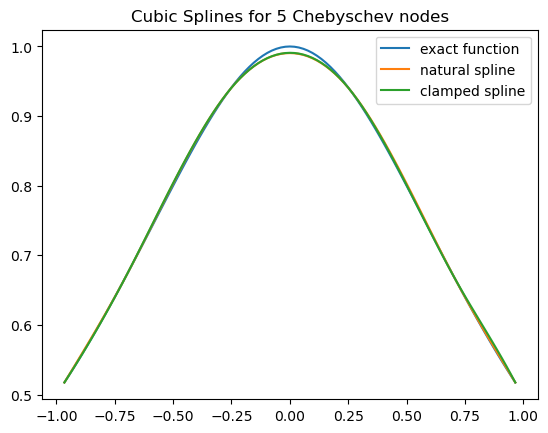

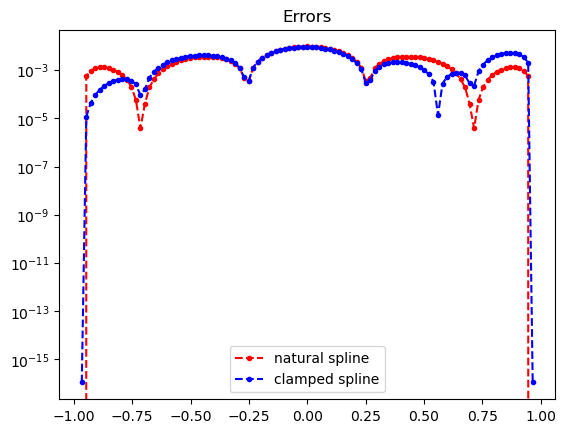

nerr =  0.0017894524759501324


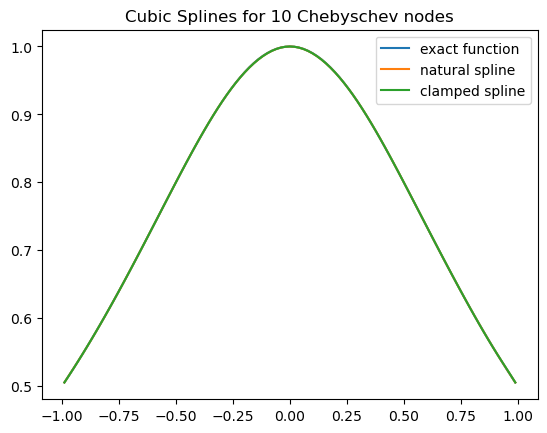

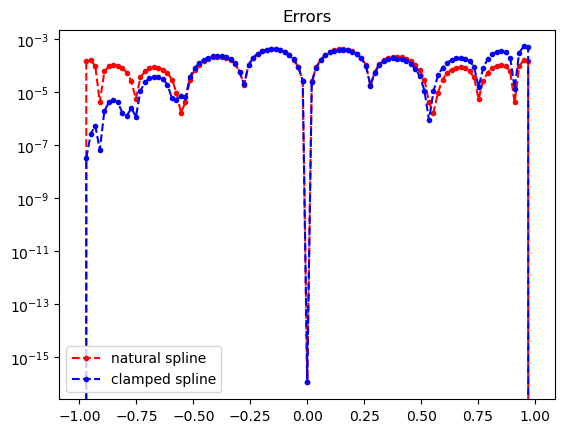

nerr =  0.0003208197060244622


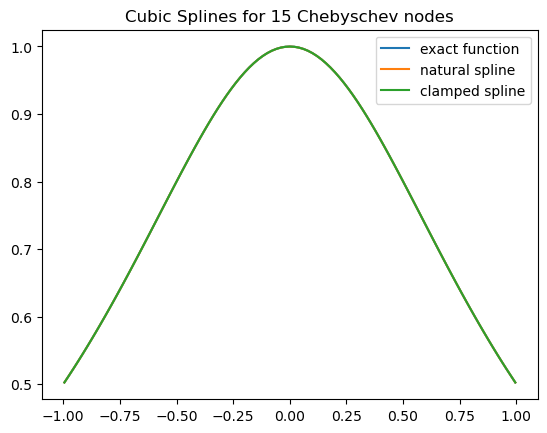

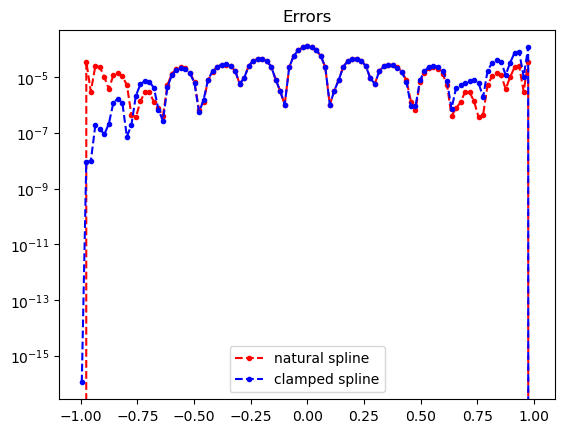

nerr =  9.401273976062557e-05


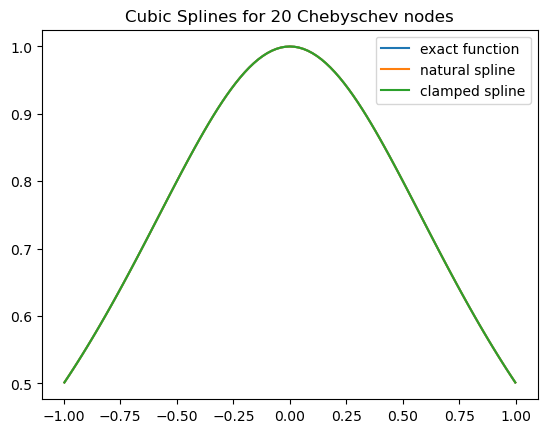

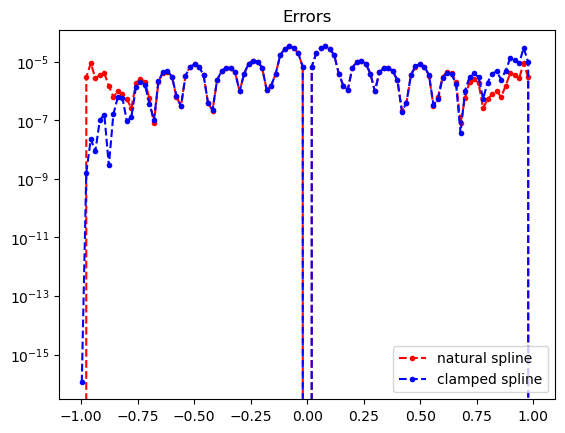

In [139]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numpy.linalg import inv 
from numpy.linalg import norm


def driver(Nint):
   
    f = lambda x: 1./(1.+x**2)
    fp = lambda x: -2*x/(1.+x**2)**2
    a = -1
    b = 1
    
    ''' number of intervals'''
    xint2 = np.linspace(-1,1,Nint+1)
# create chebychev nodes
    xint = np.zeros(Nint+1)
    for j in range(1,Nint+2):
        xint[j-1] = np.cos(np.pi*(2*j-1)/(2*(Nint+1)))

# scale  for the interval
    m = (b-a)/2 
    c = (a+b)/2
    xint = m*xint+c
    xint = xint[::-1]
    #xint = xint2
    yint = f(xint)
    yint2 = f(xint)
    yp_b = np.zeros(2)
    yp_b[0] = fp(xint[0])
    yp_b[1] = fp(xint[Nint])
    
    ''' create points you want to evaluate at'''
    Neval = 100
    xeval =  np.linspace(xint[0],xint[Nint],Neval+1)
    
    
    
    (M,C,D) = create_natural_spline(yint2,xint,Nint)
    (Mc,Cc,Dc) = create_clamped_spline(yint,yp_b, xint,Nint)    
    
    yeval = eval_cubic_spline(xeval,Neval,xint,Nint,M,C,D)
    yevalc = eval_cubic_spline(xeval,Neval,xint,Nint,Mc,Cc,Dc)
    
#    print('yeval = ', yevalc)
    
    ''' evaluate f at the evaluation points'''
    fex = f(xeval)
        
    nerr = norm(fex-yeval)
    print('nerr = ', nerr)
    
    plt.figure()    
    plt.plot(xeval,fex,label='exact function')
    plt.plot(xeval,yeval,label='natural spline') 
    plt.plot(xeval,yevalc,label='clamped spline') 
    plt.title(f'Cubic Splines for {Nint} Chebyschev nodes')
    plt.legend()
    plt.show()
     
    err = abs(yeval-fex)
    errc = abs(yevalc-fex)
    plt.figure() 
    plt.semilogy(xeval,err,'ro--', markersize = 3, label='natural spline')
    plt.semilogy(xeval,errc,'bo--', markersize = 3, label='clamped spline')
    plt.title("Errors")
    plt.legend()
    plt.show()
    
def create_natural_spline(yint,xint,N):

#    create the right  hand side for the linear system
    b = np.zeros(N+1)
#  vector values
    h = np.zeros(N+1)  
    for i in range(1,N):
       hi = xint[i]-xint[i-1]
       hip = xint[i+1] - xint[i]
       b[i] = (yint[i+1]-yint[i])/hip - (yint[i]-yint[i-1])/hi
       h[i-1] = hi
       h[i] = hip

#  create matrix so you can solve for the M values
# This is made by filling one row at a time 
    A = np.zeros((N+1,N+1))
    A[0][0] = 1.0
    for j in range(1,N):
       A[j][j-1] = h[j-1]/6
       A[j][j] = (h[j]+h[j-1])/3 
       A[j][j+1] = h[j]/6
    A[N][N] = 1

    Ainv = inv(A)
    
    M  = Ainv.dot(b)

#  Create the linear coefficients
    C = np.zeros(N)
    D = np.zeros(N)
    for j in range(N):
       C[j] = yint[j]/h[j]-h[j]*M[j]/6
       D[j] = yint[j+1]/h[j]-h[j]*M[j+1]/6
    return(M,C,D)

def create_clamped_spline(yint,yp_b, xint,N):

#    create the right  hand side for the linear system
    b = np.zeros(N+1)
#  vector values
    h = np.zeros(N+1)  
    for i in range(1,N):
       hi = xint[i]-xint[i-1]
       hip = xint[i+1] - xint[i]
       b[i] = (yint[i+1]-yint[i])/hip - (yint[i]-yint[i-1])/hi
       h[i-1] = hi
       h[i] = hip
    b[0]  = -yp_b[0] +(yint[1]-yint[0])/h[0]
    b[N] = -yp_b[1] +(yint[N]-yint[N-1])/h[N-1]

#  create matrix so you can solve for the M values
# This is made by filling one row at a time 
    A = np.zeros((N+1,N+1))
    A[0][0] = h[0]/3.
    A[0][1] = h[0]/6.
    for j in range(1,N):
       A[j][j-1] = h[j-1]/6
       A[j][j] = (h[j]+h[j-1])/3 
       A[j][j+1] = h[j]/6
    A[N][N] = h[N-1]/3
    A[N][N-1] = h[N-1]/6

    Ainv = inv(A)
    
    M  = Ainv.dot(b)

#  Create the linear coefficients
    C = np.zeros(N)
    D = np.zeros(N)
    for j in range(N):
       C[j] = yint[j]/h[j]-h[j]*M[j]/6
       D[j] = yint[j+1]/h[j]-h[j]*M[j+1]/6
    return(M,C,D)


       
def eval_local_spline(xeval,xi,xip,Mi,Mip,C,D):
# Evaluates the local spline as defined in class
# xip = x_{i+1}; xi = x_i
# Mip = M_{i+1}; Mi = M_i

    hi = xip-xi
    yeval = (Mi*(xip-xeval)**3 +(xeval-xi)**3*Mip)/(6*hi) \
            + C*(xip-xeval) + D*(xeval-xi)
    return yeval 
    
    
def  eval_cubic_spline(xeval,Neval,xint,Nint,M,C,D):
    
    yeval = np.zeros(Neval+1)
    
    for j in range(Nint):
        '''find indices of xeval in interval (xint(jint),xint(jint+1))'''
        '''let ind denote the indices in the intervals'''
        atmp = xint[j]
        btmp= xint[j+1]
        
#   find indices of values of xeval in the interval
        ind= np.where((xeval >= atmp) & (xeval <= btmp))
        xloc = xeval[ind]
#        print('atmp =', atmp)
#       print('btmp =', btmp)
#        print('ind =', ind)
#       print('xloc =', xloc)
#        return

# evaluate the spline
        yloc = eval_local_spline(xloc,atmp,btmp,M[j],M[j+1],C[j],D[j])
#        print('yloc = ', yloc)
#   copy into yeval
        yeval[ind] = yloc

    return(yeval)
           
for n in range(1, 5):
    driver(5*n)               



### **Problem 4**

Consider the task of approximating a periodic function such as f(x) = sin(10x) on the interval
[0, 2π] using the cubic spline. How do you modify the end point conditions on the coefficients
so that the spline is naturally periodic?

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numpy.linalg import inv 
from numpy.linalg import norm


def driver(Nint):
   
    f = lambda x: 1./(1.+x**2)
    fp = lambda x: -2*x/(1.+x**2)**2
    a = -5
    b = 5   
    
    ''' number of intervals'''
    xint2 = np.linspace(a,b,Nint+1)
# create chebychev nodes
#    xint = np.zeros(Nint+1)
#    for j in range(1,Nint+2):
#       xint[j-1] = np.cos(np.pi*(2*j-1)/(2*(Nint+1)))
# scale  for the interval
#    m = (b-a)/2 
#    c = (a+b)/2
#    xint = m*xint+c
#    xint = xint[::-1]
    xint = xint2
    yint = f(xint)
    yint2 = f(xint2)
    yp_b = np.zeros(2)
    yp_b[0] = fp(xint[0])
    yp_b[1] = fp(xint[Nint])
    
    ''' create points you want to evaluate at'''
    Neval = 100
    xeval =  np.linspace(xint[0],xint[Nint],Neval+1)
    
    
    
    (M,C,D) = create_natural_spline(yint2,xint2,Nint)
    (Mc,Cc,Dc) = create_clamped_spline(yint,yp_b, xint,Nint)    
    
    yeval = eval_cubic_spline(xeval,Neval,xint2,Nint,M,C,D)
    yevalc = eval_cubic_spline(xeval,Neval,xint,Nint,Mc,Cc,Dc)
    
#    print('yeval = ', yevalc)
    
    ''' evaluate f at the evaluation points'''
    fex = f(xeval)
        
    nerr = norm(fex-yeval)
    print('nerr = ', nerr)
    
    plt.figure()    
    plt.plot(xeval,fex,label='exact function')
    plt.plot(xeval,yeval,label='natural spline') 
    plt.plot(xeval,yevalc,label='clamped spline') 
    plt.title(f'Cubic Splines for {Nint} nodes')
    plt.legend()
    plt.show()
     
    err = abs(yeval-fex)
    errc = abs(yevalc-fex)
    plt.figure() 
    plt.semilogy(xeval,err,'ro--', markersize = 3, label='natural spline')
    plt.semilogy(xeval,errc,'bo--', markersize = 3, label='clamped spline')
    plt.title("Errors")
    plt.legend()
    plt.show()
    
def create_natural_spline(yint,xint,N):

#    create the right  hand side for the linear system
    b = np.zeros(N+1)
#  vector values
    h = np.zeros(N+1)  
    for i in range(1,N):
       hi = xint[i]-xint[i-1]
       hip = xint[i+1] - xint[i]
       b[i] = (yint[i+1]-yint[i])/hip - (yint[i]-yint[i-1])/hi
       h[i-1] = hi
       h[i] = hip

#  create matrix so you can solve for the M values
# This is made by filling one row at a time 
    A = np.zeros((N+1,N+1))
    A[0][0] = 1.0
    for j in range(1,N):
       A[j][j-1] = h[j-1]/6
       A[j][j] = (h[j]+h[j-1])/3 
       A[j][j+1] = h[j]/6
    A[N][N] = 1

    Ainv = inv(A)
    
    M  = Ainv.dot(b)

#  Create the linear coefficients
    C = np.zeros(N)
    D = np.zeros(N)
    for j in range(N):
       C[j] = yint[j]/h[j]-h[j]*M[j]/6
       D[j] = yint[j+1]/h[j]-h[j]*M[j+1]/6
    return(M,C,D)

def create_clamped_spline(yint,yp_b, xint,N):

#    create the right  hand side for the linear system
    b = np.zeros(N+1)
#  vector values
    h = np.zeros(N+1)  
    for i in range(1,N):
       hi = xint[i]-xint[i-1]
       hip = xint[i+1] - xint[i]
       b[i] = (yint[i+1]-yint[i])/hip - (yint[i]-yint[i-1])/hi
       h[i-1] = hi
       h[i] = hip
    b[0]  = -yp_b[0] +(yint[1]-yint[0])/h[0]
    b[N] = -yp_b[1] +(yint[N]-yint[N-1])/h[N-1]

#  create matrix so you can solve for the M values
# This is made by filling one row at a time 
    A = np.zeros((N+1,N+1))
    A[0][0] = h[0]/3.
    A[0][1] = h[0]/6.
    for j in range(1,N):
       A[j][j-1] = h[j-1]/6
       A[j][j] = (h[j]+h[j-1])/3 
       A[j][j+1] = h[j]/6
    A[N][N] = h[N-1]/3
    A[N][N-1] = h[N-1]/6

    Ainv = inv(A)
    
    M  = Ainv.dot(b)

#  Create the linear coefficients
    C = np.zeros(N)
    D = np.zeros(N)
    for j in range(N):
       C[j] = yint[j]/h[j]-h[j]*M[j]/6
       D[j] = yint[j+1]/h[j]-h[j]*M[j+1]/6
    return(M,C,D)


       
def eval_local_spline(xeval,xi,xip,Mi,Mip,C,D):
# Evaluates the local spline as defined in class
# xip = x_{i+1}; xi = x_i
# Mip = M_{i+1}; Mi = M_i

    hi = xip-xi
    yeval = (Mi*(xip-xeval)**3 +(xeval-xi)**3*Mip)/(6*hi) \
            + C*(xip-xeval) + D*(xeval-xi)
    return yeval 
    
    
def  eval_cubic_spline(xeval,Neval,xint,Nint,M,C,D):
    
    yeval = np.zeros(Neval+1)
    
    for j in range(Nint):
        '''find indices of xeval in interval (xint(jint),xint(jint+1))'''
        '''let ind denote the indices in the intervals'''
        atmp = xint[j]
        btmp= xint[j+1]
        
#   find indices of values of xeval in the interval
        ind= np.where((xeval >= atmp) & (xeval <= btmp))
        xloc = xeval[ind]
#        print('atmp =', atmp)
#       print('btmp =', btmp)
#        print('ind =', ind)
#       print('xloc =', xloc)
#        return

# evaluate the spline
        yloc = eval_local_spline(xloc,atmp,btmp,M[j],M[j+1],C[j],D[j])
#        print('yloc = ', yloc)
#   copy into yeval
        yeval[ind] = yloc

    return(yeval)
           
for n in range(1, 5):
    driver(5*n)               

